# HomeWork -4
## Objective
 In this homework, you will design a python class that encapsulates common univariate/bivariate analysis tasks. You will practice object oriented programing (OOP) while applying descriptive statistics and visualization to summarize your data and explore the relationship between two variables. 
 
 - Use the example provided in the class activity and expand it. The initializer of the class should take data and print out its shape and column names. 
 - Additionally, your class should include at least 5 methods (function) to do either univariate or bivariate analysis of your choice. 
 - Provide markdowns or comments for each part of your code.  

  - Create an instance of your class using Penguin data and use it to analyze it.
  
  - For each analysis you perform, write 1-2 sentence before that function call that clearly state
    the question you are trying to answer with that analysis. For example: "In this analysis I want to see what is the average mass for each species." 

  


In [26]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


sns.set(style="whitegrid")
penguins = sns.load_dataset('penguins')


class VariateAnalyzer:

    ## Constructor
    def __init__(self, data):
        
        ## [dataSet] attribute
        self.dataSet = data.copy()

        print(f"loaded {len(data)} rows, {len(data.columns)} columns")
        
        columnNames = "Columns: "
        for a in data.columns:
            columnNames += a + ", "
        columnNames = columnNames.removesuffix(", ")
        print(columnNames)

    
    ## Univariate analysis - distribution of Body Mass values across the whole data set
    def numeric_distribute(self, numerical):
        """Histogram: distribution of data point values for numercial continuous variable 
        """
        plt.figure(figsize=(10,6))
        sns.histplot(data = self.dataSet, x = numerical)
        plt.title(f"Distribution for {numerical}")
        plt.show()

    ## Univariate analysis - comparing count of penguins of each Sex  
    def categoric_amount(self, category):
        """Bar graph: frequency of data points in each category 
        """
        plt.figure(figsize=(10,6))
        sns.countplot(data = self.dataSet, x = category, hue=category, palette='Set3')
        plt.ylim(150, 170)
        plt.yticks(np.arange(150, 170, 1))
        plt.title(f"Count of {category}")
        plt.show()
    
    ### Bivariate analysis - relationship between Body Mass and Flipper Length, looking at the whole data set
    def relation_numerical(self, measure1, measure2):
        """Scatterplot: distribution of data points based on quantitative variables  
        """
        plt.figure(figsize=(10,6))
        sns.scatterplot(data = self.dataSet, x = measure1, y = measure2)
        plt.title(f"{measure1} vs {measure2}")
        plt.show()
    
    ### Bivariate analysis - comparing each Sex's average of Bill Depth measurements 
    def numer_per_categor(self, categor, numer):
        """Violin plot: distribution of numeric variable values, per category 
        """
        plt.figure(figsize=(10,6))
        sns.violinplot(data = self.dataSet, x = categor, y = numer, hue=categor, palette='Set3', legend=False)
        plt.ylim(10,24)
        plt.yticks(np.arange(10,24))
        plt.title(f"{categor} vs {numer}")
        plt.show()

    ### Bivariate/Multivariate analysis - comparing Body Mass averages for each Island;
    ###                                   uses hue to differentiate between Species within each Island
    def quant_per_categ(self, cat, quant, hue=None):
        """Box plot: distribution of quantitative values, per category; each category sorted further into sub-categories  
        """
        plt.figure(figsize=(12,7))
        sns.boxplot(data = self.dataSet, x = cat, y = quant, width=0.8, gap=0.25, hue = hue)
        plt.title(f"{quant} for each {cat}")
        plt.show()



In [27]:
testAnalyze = VariateAnalyzer(penguins)
print()

loaded 344 rows, 7 columns
Columns: species, island, bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g, sex



In this analysis, I want to see what ranges of body mass are most and least common within the population sample:




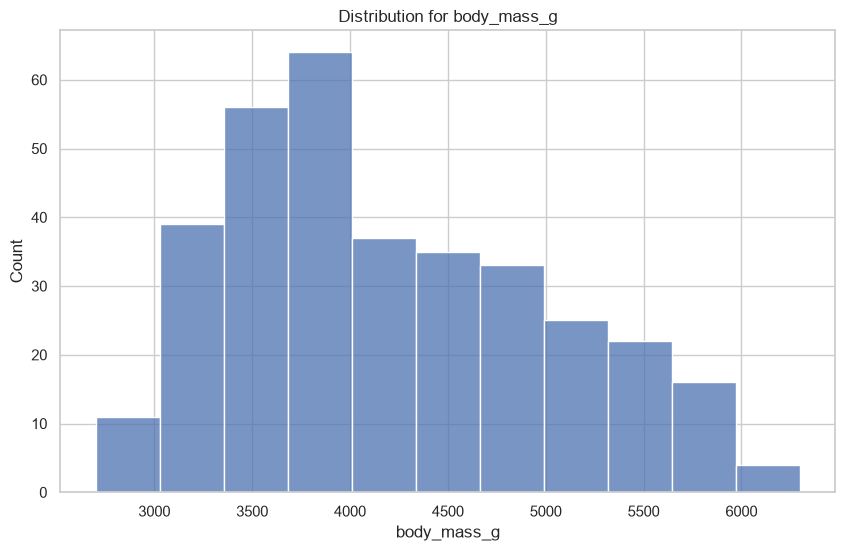

In [28]:

print("In this analysis, I want to see what ranges of body mass are most and least common within the population sample:\n\n")
testAnalyze.numeric_distribute('body_mass_g')


In this analysis, I want to compare how many male penguins to how many
female penguins were included within the sample population:



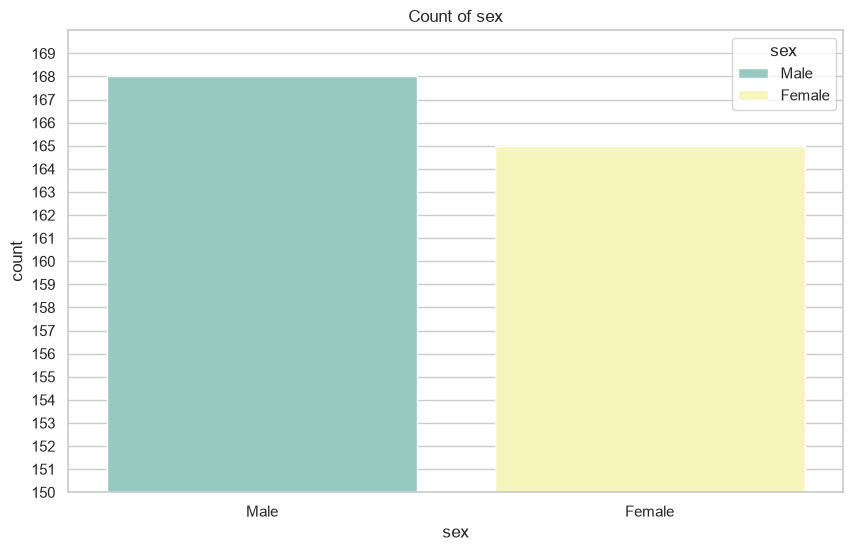

In [29]:

print("In this analysis, I want to compare how many male penguins to how many")
print("female penguins were included within the sample population:\n")
testAnalyze.categoric_amount('sex')


In this analysis, I want to see if there is a relationship between Body Mass and
Flipper Length, looking across the whole sample population:



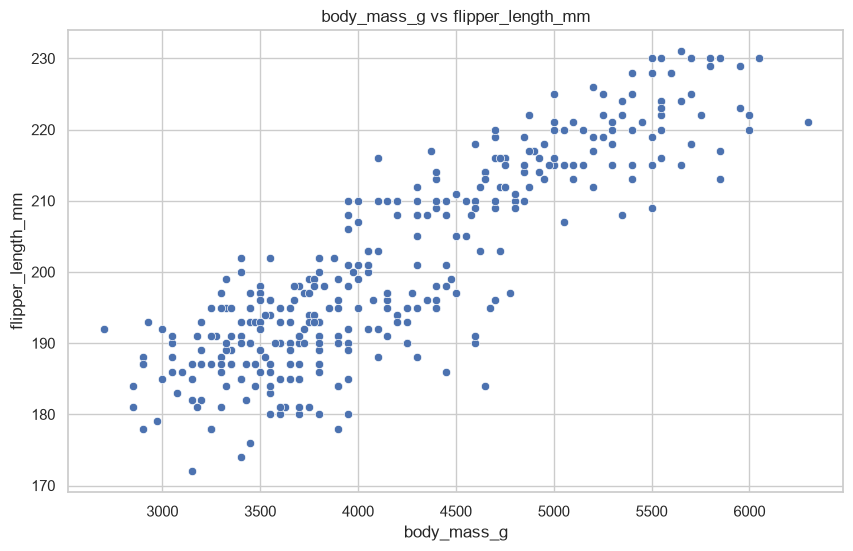

In [30]:

print("In this analysis, I want to see if there is a relationship between Body Mass and")
print("Flipper Length, looking across the whole sample population:\n")
testAnalyze.relation_numerical('body_mass_g', 'flipper_length_mm')


In this analysis, I want to see the differences/similarities of average Bill Depth between Sexes:



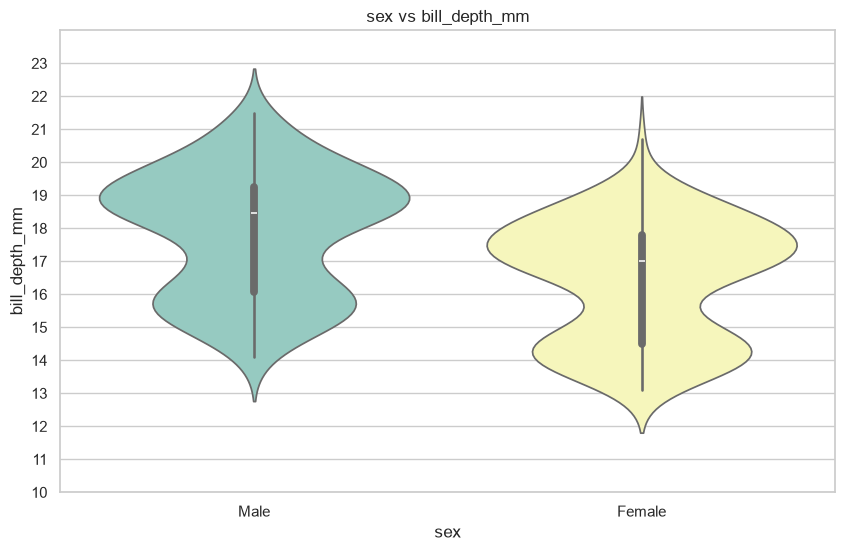

In [31]:

print("In this analysis, I want to see the differences/similarities of average Bill Depth between Sexes:\n")
testAnalyze.numer_per_categor('sex', 'bill_depth_mm')


In this analysis, I want to compare the average Body Mass across each Island; taking into
consideration each Species group present on each island:



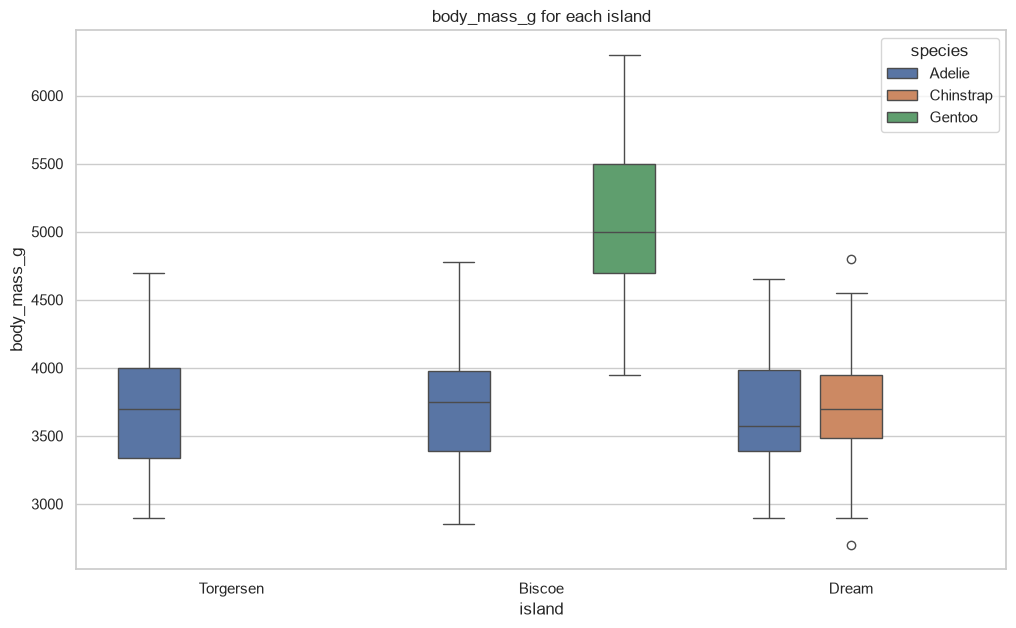

In [32]:

print("In this analysis, I want to compare the average Body Mass across each Island; taking into")
print("consideration each Species group present on each island:\n")
testAnalyze.quant_per_categ('island', 'body_mass_g', 'species')
